# Analisi di notizie del New York Times: topic e sentiment

Questo notebook analizza un campione di **66'038 articoli del New York Times (1985-2018)**, circa 2'000 per anno, e confronta diversi metodi di NLP:

1. **Topic**: ogni articolo viene assegnato a uno dei 13 *IPTC Media Topics* con una classificazione *zero-shot* basata sugli embedding (nessun addestramento).
2. **Sentiment**: il tono di ogni articolo viene calcolato con due metodi, **VADER** (dizionario di parole) e **RoBERTa** (modello transformer).
3. **Validazione**: 200 articoli vengono etichettati da un LLM e usati come riferimento per misurare, con confusion matrix e accuracy, quale metodo funziona meglio.

Il codice vero sta nel pacchetto `analisi_notizie` (cartella `src/`): il notebook richiama le funzioni e mostra i risultati.

## 0. Setup
`autoreload` ricarica i moduli di `analisi_notizie` quando vengono modificati, senza dover riavviare il kernel.

In [7]:
# Configurazione per il caricamento automatico dei moduli modificati
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
# importazione dei moduli necessari
import numpy as np
import pandas as pd
import sweetviz as sv

from analisi_notizie.config import DATA_DIR, DATASET_DIR, IPTC_MEDIA_TOPIC

## 1. Esplorazione del dataset
Report interattivo di Sweetviz (si apre nel browser e viene salvato come `SWEETVIZ_REPORT.html`): tipi di colonne, valori mancanti e distribuzioni.

In [11]:
# DATASET_DIR è già il percorso del file csv
df = pd.read_csv(DATASET_DIR)

# report html interattivo con statistiche e distribuzioni di ogni colonna
my_report = sv.analyze(df)
my_report.show_html()

Feature: word_count                          |███▌      | [ 36%]   00:01 -> (00:02 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal for Roboto, now using 500.
Feature: source                              |█████     | [ 50%]   00:02 -> (00:02 left)findfont: Failed to find font weight normal for Roboto, now using 500.
findfont: Failed to find font weight normal

Report SWEETVIZ_REPORT.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


## 2. Pulizia
Tengo solo le colonne utili e le rinomino, poi rimuovo gli articoli senza titolo o senza testo e i duplicati.

In [13]:
import analisi_notizie.cleaning as mycleaning

df = pd.read_csv(DATASET_DIR)

# colonne da tenere (nomi originali) e i loro nuovi nomi, nello stesso ordine
previous_columns = ["writer_name", "pub_date", "section_name", "main_headline", "body_text"]
new_columns = ["author", "date", "topic", "headline", "full_article"]
# colonne che non devono contenere valori mancanti e duplicati 
no_missing = ["headline", "full_article"]
no_duplicate = ["full_article"]

df, report = mycleaning.clean_news(df, previous_columns, new_columns, no_missing, no_duplicate)

print("Cleaning report:")
for key, value in report.items():
    print(f"{key}: {value}")

df.to_csv(DATA_DIR / "NYT_news_processed.csv", index=False)

Cleaning report:
initial_rows: 66038
initial_columns: 13
dropped_columns: ['_key', 'snippet', 'word_count', 'score', 'source', 'type_of_material', 'document_type', 'print_headline']
rows_removed_missing: 1828
rows_removed_duplicates: 599
final_rows: 63611
final_columns: 5


## 3. Embedding
Trasformo ogni articolo (titolo + testo) e ogni descrizione dei topic in un vettore con `all-MiniLM-L6-v2`. Testi con significato simile finiscono vicini nello spazio vettoriale.

In [14]:
import torch
from sentence_transformers import SentenceTransformer

from analisi_notizie.config import IPTC_MEDIA_TOPIC_DESC

# stesso modello per articoli e descrizioni dei topic, così i vettori sono confrontabili
model = SentenceTransformer("all-MiniLM-L6-v2")
# un vettore per articolo: titolo + testo uniti in un'unica stringa
news_encoded = model.encode((df["headline"] + " " + df["full_article"]).tolist())
topic_encoded = model.encode(IPTC_MEDIA_TOPIC_DESC)

# salvo gli embedding per non doverli ricalcolare
np.save(DATA_DIR / "news_encoded.npy", news_encoded)
np.save(DATA_DIR / "topic_encoded.npy", topic_encoded)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1388.49it/s]


Visualizzazione in 3D degli embedding dei topic (ridotti con la PCA): ogni freccia è un topic, e topic con descrizioni simili puntano in direzioni vicine. 
(grafico carino, ma non fornisce informazioni utili)

In [12]:
# Visualizzo gli embedding in 3D
from analisi_notizie.graphs import embedding_to_3d

topic_encoded = np.load(DATA_DIR / "topic_encoded.npy")

embedding_to_3d(topic_encoded, IPTC_MEDIA_TOPIC)

## 4. Classificazione dei topic (zero-shot)
Ogni articolo va al topic con la descrizione più simile (similarità coseno tra gli embedding). Il grafico mostra la quota di ogni topic nel tempo.

In [15]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from analisi_notizie.analisi import classify
from analisi_notizie.config import IPTC_MEDIA_TOPIC
from analisi_notizie.graphs import topic_share

# classificazione zero-shot: nessun addestramento, solo similarità tra vettori
# ogni articolo va al topic con la descrizione più simile; labels traduce gli indici nei nomi dei topic
pred, similarity, full_matrix = classify(news_encoded, topic_encoded, labels=IPTC_MEDIA_TOPIC)

# salvo i risultati
df["pred_topic"] = pred
df.to_csv(DATA_DIR / "NYT_news_processed.csv", index=False)

C:\Users\napol\Documents\SECOND BRAIN\10_Projects\Analisi_news\src\analisi_notizie\graphs.py:80: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  date = pd.to_datetime(dates, dayfirst=True)


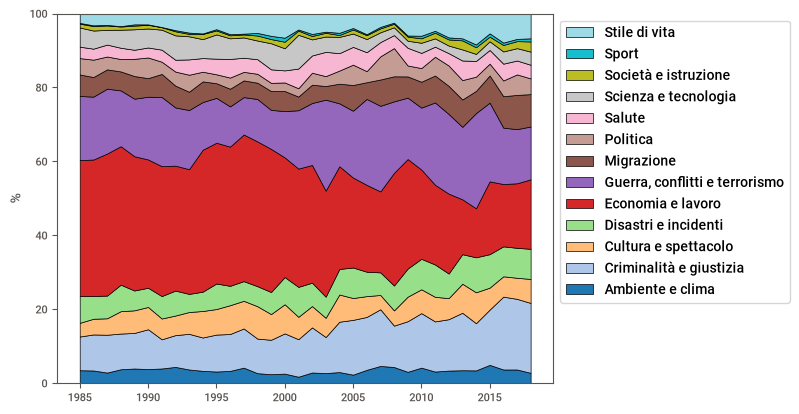

In [16]:
# Quota di ogni topic nel tempo (per anno, o per mese se c'è un solo anno)
df = pd.read_csv(DATA_DIR / "NYT_news_processed.csv")
topic_share(df)

## 5. Sentiment con VADER
VADER somma il peso emotivo delle parole presenti in un dizionario e restituisce un punteggio `compound` tra -1 e 1, che trasformo in `negative` / `neutral` / `positive` con le soglie standard (±0.05).

Nota: VADER è pensato per testi brevi; su articoli lunghi il punteggio tende a saturare verso ±1, quindi quasi nessun articolo risulta neutro.

C:\Users\napol\Documents\SECOND BRAIN\10_Projects\Analisi_news\src\analisi_notizie\graphs.py:80: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  date = pd.to_datetime(dates, dayfirst=True)
findfont: Failed to find font weight normal for Roboto, now using 500.


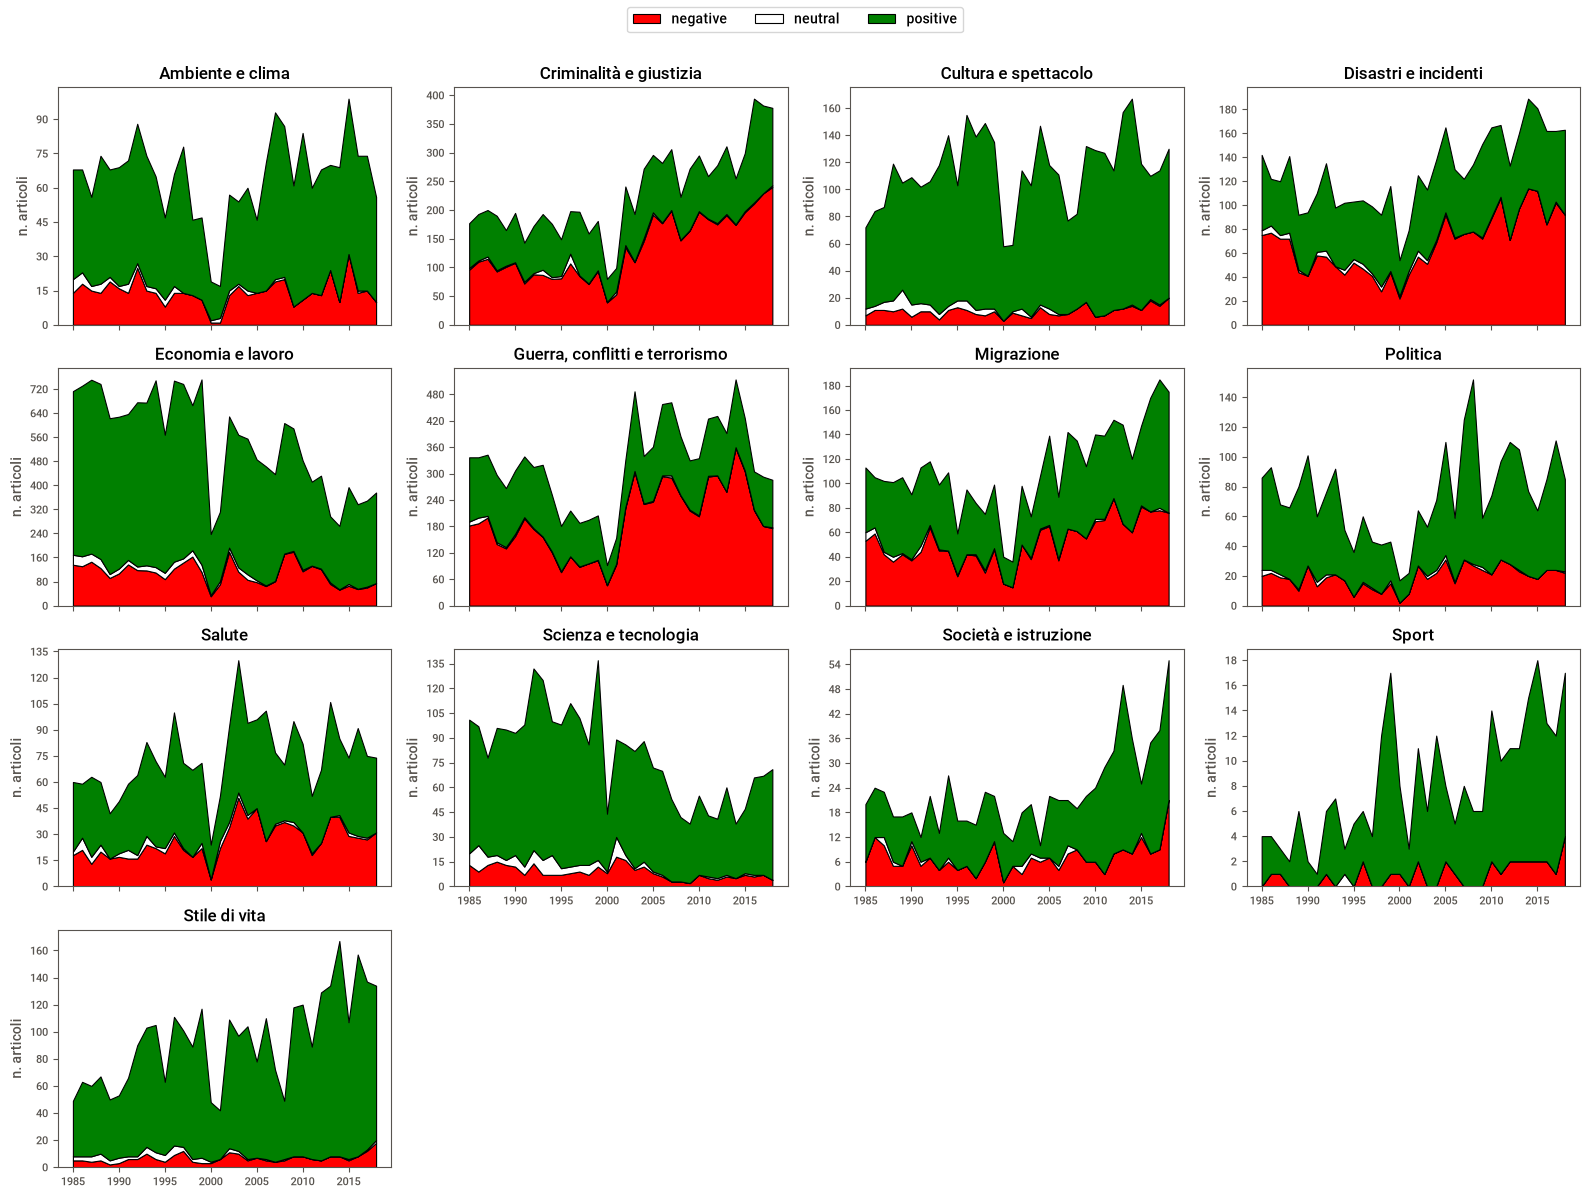

In [17]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

from analisi_notizie.analisi import label_sentiment
from analisi_notizie.graphs import sentiment_by_topic

# Inizializza l'analizzatore
sia = SentimentIntensityAnalyzer()

# polarity_scores restituisce un dict (neg, neu, pos, compound): ogni chiave diventa una colonna
scores = df["full_article"].apply(lambda t: pd.Series(sia.polarity_scores(t)))
# compound va da -1 a 1: lo trasformo in positive / neutral / negative
df["sentiment_label"] = scores["compound"].apply(label_sentiment)

# salvo i risultati
df.to_csv(DATA_DIR / "NYT_news_processed.csv", index=False)

# Numero di articoli positivi / negativi / neutri nel tempo, un grafico per topic
sentiment_by_topic(df, sentiment_col="sentiment_label")

## 6. Sentiment con RoBERTa
Modello `cardiffnlp/twitter-roberta-base-sentiment-latest`. Accetta al massimo 512 token, quindi ogni articolo viene tokenizzato e diviso in chunk; con `max_chunks=1` si usa solo il primo chunk (circa 380 parole), che dimezza i tempi.

⚠️ Il blocco è pesante: su CPU servono circa 40 minuti ogni 1'000 articoli. Il modello usa la GPU in automatico se disponibile (es. Google Colab): con GPU l'intero dataset richiede circa 30 minuti.

In [ ]:
# Problemi: in caso di molti chunk, la memoria si esaurisce.
from analisi_notizie.analisi import aggregate_chunks, chunk_prediction, df_to_token


# testo -> primo chunk di token (max 510) -> probabilità -> una classe per articolo
df = aggregate_chunks(df, chunk_prediction(df_to_token(df, max_chunks=1)))

# salvo solo l'etichetta di sentiment: le probabilità per classe non servono più
df = df.drop(columns=["negative", "neutral", "positive"], errors="ignore")
df.to_csv(DATA_DIR / "NYT_news_processed.csv", index=False)

C:\Users\napol\Documents\SECOND BRAIN\10_Projects\Analisi_news\src\analisi_notizie\graphs.py:80: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  date = pd.to_datetime(dates, dayfirst=True)


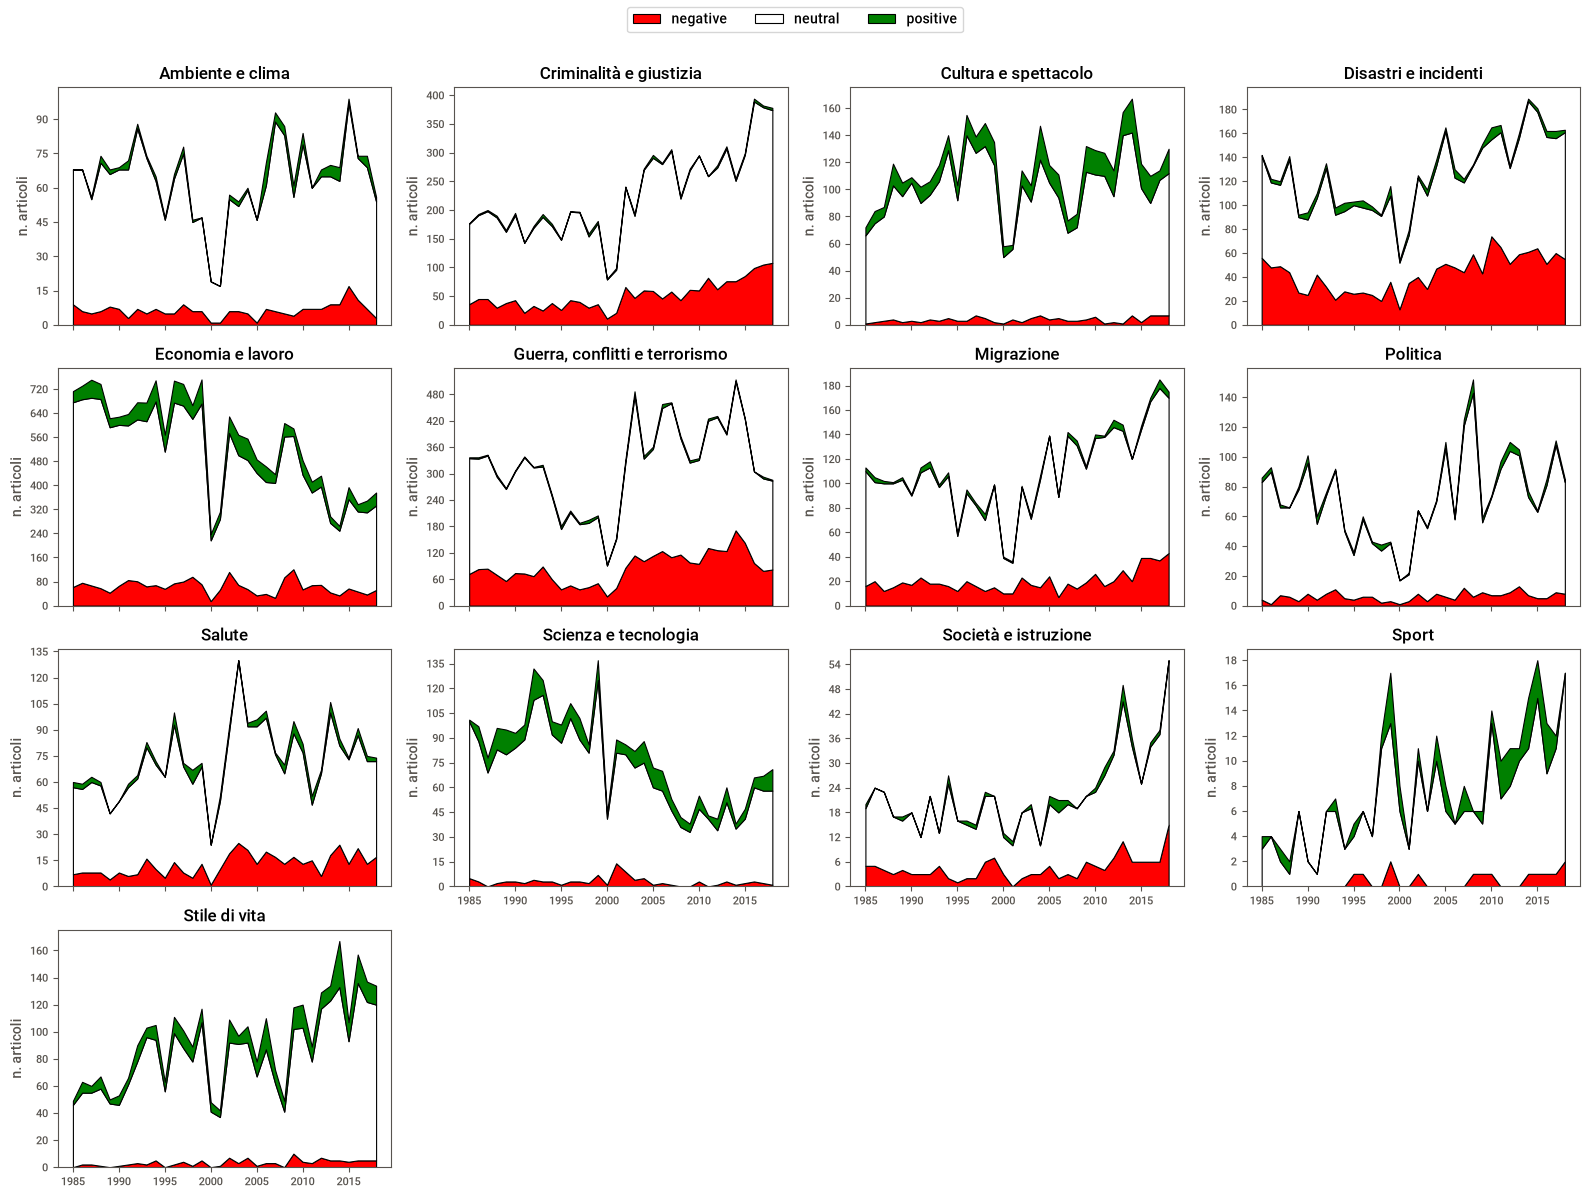

In [18]:
from analisi_notizie.graphs import sentiment_by_topic
df = pd.read_csv(DATA_DIR / "NYT_news_processed.csv")
# Stesso grafico della sentiment analysis 1, con le etichette del modello
sentiment_by_topic(df, sentiment_col="sentiment")

## 7. Validazione con un LLM
Non esiste un'etichetta "vera" per questi articoli, quindi uso un LLM come riferimento: estraggo 200 articoli a caso, li faccio classificare all'LLM (topic e sentiment, con le stesse definizioni usate dagli altri metodi) e confronto le sue etichette con quelle dei tre metodi.

In [ ]:
from analisi_notizie.analisi import llm_prompt_files

# 200 articoli a caso -> .data/llm_prompt_1.txt e llm_prompt_2.txt (25 articoli ciascuno) da incollare nell'LLM
df = pd.read_csv(DATA_DIR / "NYT_news_processed.csv")
campione = llm_prompt_files(df, DATA_DIR)

**Passo manuale**
1. Apri `.data/llm_prompt_1.txt`, copia tutto e incollalo nell'LLM.
2. Copia la risposta (solo il CSV) in un nuovo file `.data/llm_labels.csv`.
3. Ripeti con `llm_prompt_2.txt` … `llm_prompt_8.txt` e accoda ogni risposta allo stesso file, **senza** ripetere la riga `id;topic;sentiment`.

In [21]:
from analisi_notizie.analisi import load_llm_labels

# carico le risposte dell'LLM, stampo eventuali errori e le aggiungo al df come llm_topic e llm_sentiment
df = load_llm_labels(df, DATA_DIR / "llm_labels.csv", campione.index)
df.to_csv(DATA_DIR / "NYT_news_processed.csv", index=False)

ID mancanti: []
ID in più: [] duplicati: []
Topic non validi: {}
Sentiment non validi: {}


### Confronto
Righe = etichetta dell'LLM, colonne = predizione del metodo. Più i numeri sono concentrati sulla diagonale, più il metodo è d'accordo con l'LLM.

Topic - embedding
                                precision    recall  f1-score   support

              Ambiente e clima       0.33      0.50      0.40         2
       Criminalità e giustizia       0.48      0.57      0.52        21
          Cultura e spettacolo       0.38      0.38      0.38         8
          Disastri e incidenti       0.40      1.00      0.57         6
             Economia e lavoro       0.93      0.61      0.73        84
Guerra, conflitti e terrorismo       0.38      0.94      0.54        17
                    Migrazione       0.07      1.00      0.12         1
                      Politica       1.00      0.21      0.35        38
                        Salute       0.50      1.00      0.67         3
          Scienza e tecnologia       0.33      0.29      0.31         7
          Società e istruzione       0.50      0.20      0.29        10
                         Sport       1.00      1.00      1.00         1
                 Stile di vita       0.08    

Topic - embedding      0.54
Sentiment - VADER      0.46
Sentiment - RoBERTa    0.59
Name: accuracy, dtype: float64

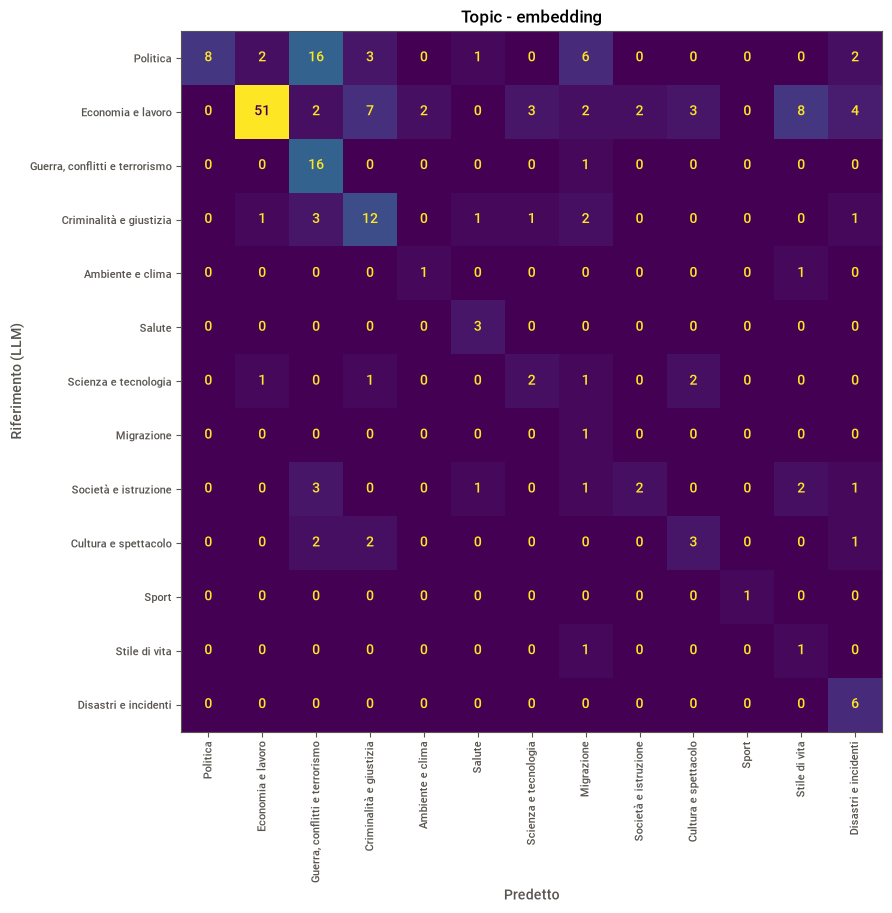

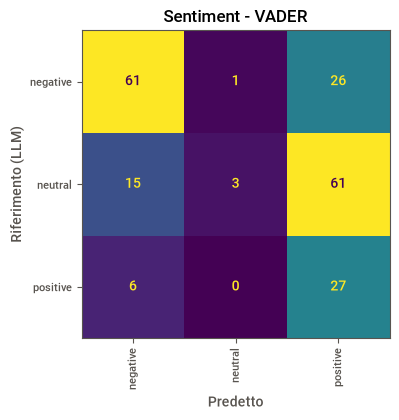

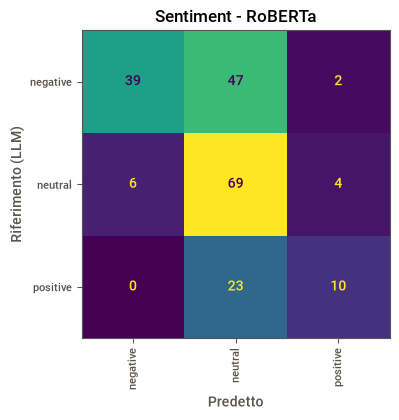

In [22]:
from analisi_notizie.analisi import llm_accuracy
from analisi_notizie.graphs import llm_confusion_matrices

# confusion matrix e accuracy di ogni metodo, usando l'LLM come riferimento
llm_confusion_matrices(df)
llm_accuracy(df)

## 8. Conclusioni
Accordo con le etichette dell'LLM su 200 articoli:

| Metodo | Accuracy vs LLM |
|---|---|
| Topic - embedding | 0.54 |
| Sentiment - VADER | 0.46 |
| Sentiment - RoBERTa | 0.59 |

- **Topic nel tempo**: *Economia e lavoro* scende da circa il 37% (1985) al 19% (2018), *Criminalità e giustizia* sale dal 9% al 19%; *Guerra, conflitti e terrorismo* ha picchi nel 2003 e nel 2014.
- **Topic, qualità**: la classificazione zero-shot funziona bene su *Economia e lavoro* (precision 0.93) e *Guerra* (recall 0.94). Rendere più specifica la descrizione di *Scienza e tecnologia* (scoperte ed esperimenti, non aziende tech) ha quasi eliminato gli articoli di economia classificati come tecnologia. L'errore principale ora è *Politica* scambiata per *Guerra, conflitti e terrorismo* (16 casi su 38).
- **VADER** quasi non assegna mai `neutral` (2% del dataset): su testi lunghi il punteggio satura, e quasi tutto diventa positivo o negativo.
- **RoBERTa** al contrario mette la maggior parte degli articoli in `neutral` (78%): è addestrato su tweet e misura il tono di chi scrive, mentre gli articoli del NYT hanno un registro volutamente distaccato anche quando gli eventi sono negativi. Quando dice `negative` ha quasi sempre ragione (precision 0.87).
- **Tono nel tempo**: gli articoli negativi aumentano in alcuni topic, ma in proporzione al numero di articoli; una variazione reale del tono non si osserva.
- L'LLM non è la verità assoluta: questi numeri misurano l'**accordo** con l'LLM, e con 200 articoli le metriche per i topic meno frequenti sono solo indicative.